# BioLip-style video branch (Stage 1a) on MMDF
Lip-motion (biomechanics) features -> real/fake score + per-frame anomaly curve.

**Pipeline in one line:** pick paired clips -> re-encode all the same way -> MediaPipe landmarks -> align face + compute lip kinematics -> 2 s windows -> GBM + temporal CNN -> calibrate on unseen generators -> Real / Ambiguous / Fake.

Runs top to bottom, ~1 h on Colab CPU (landmark extraction is the slow part and is cached on Drive, so you can re-run after a disconnect).

## 1. Install  (if pip complains about numpy: Runtime -> Restart session, then continue from the next cell)

In [1]:
!pip -q install mediapipe huggingface_hub tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.5/41.5 MB 17.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.7/137.7 kB 13.1 MB/s eta 0:00:00


## 2. Settings, Drive, Hugging Face login

In [2]:
import os, json, time, math, subprocess, sys, urllib.request, warnings
from pathlib import Path
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd
from tqdm.auto import tqdm
from IPython.display import display
from scipy.signal import savgol_filter
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
warnings.filterwarnings("ignore")

# ---- settings (everything you might want to change)
SEED = 42
PAIRS = {"train": 200, "val": 60, "test": 100}   # real/fake pairs per generator
FPS, MAX_FRAMES = 25, 125                        # only the first 5 s of each clip
WIN, STRIDE = 50, 10                             # 2 s windows, hop of 10 frames
MIN_VALID = 0.9                                  # window needs >= 90% reliable frames
MAX_GAP = 5                                      # fill detection gaps up to 5 frames
SG_WIN, SG_POLY = 7, 3                           # Savitzky-Golay filter for derivatives
CNN_SEEDS, CNN_EPOCHS = [0, 1, 2], 40
TOPK, AUX_W = 0.4, 0.3                           # CNN: clip logit = mean of top 40% frame logits
W_CNN = 0.5                                      # ensemble weight of the CNN (rest = GBM)
TARGET_ACC = 0.95                                # accuracy wanted on non-ambiguous clips

from google.colab import drive
drive.mount("/content/drive")
ROOT = Path("/content/drive/MyDrive/btp_biolip")             # all caches + outputs live here
REENC, WAVS, LMD, OUT = ROOT/"reencoded", ROOT/"wav16k", ROOT/"landmarks", ROOT/"outputs"
for d in (REENC, WAVS, LMD, OUT): d.mkdir(parents=True, exist_ok=True)
np.random.seed(SEED)

from huggingface_hub import login, HfApi, hf_hub_download
login()   # paste a token when asked (never write it in the notebook)

Mounted at /content/drive


## 3. Landmark definitions
64 perioral points of the MediaPipe mesh (lips + jaw line + philtrum/chin) and 8 rigid 'anchor' points (eye corners, nose bridge) used only to remove head pose.

In [3]:
OUTER_UP = [61,185,40,39,37,0,267,269,270,409,291]
OUTER_LO = [146,91,181,84,17,314,405,321,375]
INNER_UP = [78,191,80,81,82,13,312,311,310,415,308]
INNER_LO = [95,88,178,87,14,317,402,318,324]
JAW      = [58,172,136,150,149,176,148,152,377,400,378,379,365,397,288]
MID      = [2,164,167,393,165,391,18,200,199]
PERIORAL = OUTER_UP + OUTER_LO + INNER_UP + INNER_LO + JAW + MID
ANCHORS  = [33,133,362,263,168,6,197,195]       # index 0 and 3 = outer eye corners
assert len(PERIORAL) == 64 and len(set(PERIORAL)) == 64

POS = {lm: i for i, lm in enumerate(PERIORAL)}  # mesh id -> column in our 64-point array
REGIONS = {"up_outer": OUTER_UP, "lo_outer": OUTER_LO, "up_inner": INNER_UP, "lo_inner": INNER_LO,
           "jaw": JAW, "mid": MID, "corner_L": [61,78,146,95], "corner_R": [291,308,375,324]}
REG_IDX = {r: [POS[l] for l in ls] for r, ls in REGIONS.items()}

## 4. Pick the clips
Train/val use FaceAdapter, Hallo2, LivePortrait; test uses AniPortrait, Hunyuan, MegActor-S (generators never seen in training). Every fake is paired with the real clip of the same id, so classes are balanced.

In [4]:
REPO = "zaqxsw0526/MMDF"
paths = [e.path for e in HfApi().list_repo_tree(REPO, repo_type="dataset", recursive=True)
         if hasattr(e, "size") and e.path.endswith(".mp4")]
index = defaultdict(dict)                         # (split, label, generator) -> {clip_id: path}
for p in paths:
    parts = p.split("/")
    if len(parts) == 4: index[tuple(parts[:3])][parts[3][:-4]] = p

rng = np.random.default_rng(SEED)
rows = []
for split in ("train", "val", "test"):
    for gen in sorted({g for (s, l, g) in index if s == split}):
        ids = sorted(set(index[(split, "real", gen)]) & set(index[(split, "fake", gen)]))   # ids that exist as real AND fake
        for cid in sorted(rng.choice(ids, size=min(PAIRS[split], len(ids)), replace=False)):
            for label, name in ((0, "real"), (1, "fake")):
                rows.append(dict(split=split, generator=gen, clip_id=cid, label=label, label_name=name, hf_path=index[(split, name, gen)][cid]))
manifest = pd.DataFrame(rows)
manifest["key"]  = manifest.split + "/" + manifest.label_name + "/" + manifest.generator + "/" + manifest.clip_id
manifest["pair"] = manifest.split + "/" + manifest.generator + "/" + manifest.clip_id

# sanity: no clip id may appear in two splits
ids_ = {s: set(manifest[manifest.split == s].clip_id) for s in ("train", "val", "test")}
print("id overlap:", len(ids_["train"] & ids_["val"]), len(ids_["train"] & ids_["test"]), len(ids_["val"] & ids_["test"]))
display(manifest.groupby(["split", "generator", "label_name"]).size().unstack())

id overlap: 0 0 0


label_name          fake  real
split generator               
test  aniportrait    100   100
      hunyuan        100   100
      megactor-s     100   100
train faceadapter    200   200
      hallo2         200   200
      liveportrait   200   200
val   faceadapter     60    60
      hallo2          60    60
      liveportrait    60    60

## 5. Download and re-encode
Real and fake files were encoded differently (codec, fps), which a model could pick up as a shortcut. So **every** clip goes through the same ffmpeg recipe: first 5 s, 25 fps, 512x512, h264 CRF 23. The 16 kHz mono wav is exported too (for the audio teammates).

In [5]:
errs = []
def download(p):
    for _ in range(3):
        try: return hf_hub_download(REPO, p, repo_type="dataset")
        except Exception as e: errs.append(repr(e)); time.sleep(3)
    return None
with ThreadPoolExecutor(8) as ex:                               # 8 threads: fewer rate-limit errors than 16
    manifest["src_path"] = list(tqdm(ex.map(download, manifest.hf_path), total=len(manifest), desc="download"))
print(f"downloaded {manifest.src_path.notna().sum()}/{len(manifest)}")
if manifest.src_path.notna().sum() == 0: raise RuntimeError("nothing downloaded, last error: " + (errs[-1] if errs else "?"))
bad = set(manifest[manifest.src_path.isna()].pair)           # drop pairs where one clip failed
manifest = manifest[~manifest.pair.isin(bad)].reset_index(drop=True)

ff_err = []
def reencode(r):
    out = REENC / (r.key + ".mp4"); out.parent.mkdir(parents=True, exist_ok=True)
    ok = out.exists()
    if not ok:
        p = subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", r.src_path, "-an", "-t", "5",
            "-vf", f"fps={FPS},scale=512:512", "-c:v", "libx264", "-preset", "veryfast", "-crf", "23", "-pix_fmt", "yuv420p", str(out)],
            capture_output=True, text=True)
        ok = p.returncode == 0
        if not ok: ff_err.append(p.stderr[-300:])
    w = WAVS / (r.key + ".wav"); w.parent.mkdir(parents=True, exist_ok=True)
    if not w.exists(): subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", r.src_path, "-vn", "-ac", "1", "-ar", "16000", "-t", "5", str(w)], capture_output=True)
    return str(out) if ok else None
rows_ = list(manifest.itertuples())
with ThreadPoolExecutor(os.cpu_count() or 2) as ex:
    manifest["reenc_path"] = list(tqdm(ex.map(reencode, rows_), total=len(rows_), desc="re-encode"))
manifest = manifest.dropna(subset=["reenc_path"]).reset_index(drop=True)
print(len(manifest), "clips ready")
if len(manifest) == 0: raise RuntimeError("no clip survived re-encoding; ffmpeg said: " + (ff_err[-1] if ff_err else "?"))

download:   0%|          | 0/2160 [00:00<?, ?it/s]

train/real/faceadapter/09247bde43e6fe20e(…): reconstructing file:   0%|          |  0.00B /  506kB            

train/fake/faceadapter/05c3299cebd0dfa11(…): reconstructing file:   0%|          |  0.00B /  896kB            

train/fake/faceadapter/02243f18a2776097a(…): reconstructing file:   0%|          |  0.00B /  641kB            

train/real/faceadapter/02243f18a2776097a(…): reconstructing file:   0%|          |  0.00B /  208kB            

...

test/fake/megactor-s/fbe2e23b73e25865301(…): downloading bytes:           |  0.00B            

test/fake/megactor-s/fd7bf1d4233938e34fd(…): downloading bytes:           |  0.00B            

downloaded 2160/2160


re-encode:   0%|          | 0/2160 [00:00<?, ?it/s]

2160 clips ready


## 6. MediaPipe landmarks
Runs in separate worker processes (MediaPipe + PyTorch in one Colab process can crash the kernel). One FaceLandmarker per clip so no tracking state leaks between videos. Each clip is saved as `landmarks/<key>.npz`; finished clips are skipped on re-run.

In [6]:
TASK = ROOT / "face_landmarker.task"
if not TASK.exists():
    urllib.request.urlretrieve("https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task", str(TASK))

# the worker script: video -> (T,64,3) lip landmarks + (T,8,3) anchors + valid flag per frame
WORKER = r"""
import sys, os, json, time
os.environ["GLOG_minloglevel"] = "2"
import numpy as np, cv2, mediapipe as mp
from mediapipe.tasks import python as mpp
from mediapipe.tasks.python import vision
cfg = json.load(open(sys.argv[1])); tasks = json.load(open(sys.argv[2]))
for src, dst in tasks:
    if os.path.exists(dst): continue
    try:
        t0 = time.perf_counter()
        fm = vision.FaceLandmarker.create_from_options(vision.FaceLandmarkerOptions(
            base_options=mpp.BaseOptions(model_asset_path=cfg["task"]), running_mode=vision.RunningMode.VIDEO, num_faces=1))
        cap = cv2.VideoCapture(src); L, A, V = [], [], []
        while len(V) < cfg["max_frames"]:
            ok, fr = cap.read()
            if not ok: break
            rgb = np.ascontiguousarray(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB)); H, W = rgb.shape[:2]
            res = fm.detect_for_video(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb), int(len(V) * 1000 / cfg["fps"]))
            if res.face_landmarks:
                p = np.array([[q.x, q.y, q.z] for q in res.face_landmarks[0]], np.float32) * np.array([W, H, W], np.float32)
                L.append(p[cfg["peri"]]); A.append(p[cfg["anc"]]); V.append(True)
            else:   # no face found in this frame
                L.append(np.full((64, 3), np.nan, np.float32)); A.append(np.full((len(cfg["anc"]), 3), np.nan, np.float32)); V.append(False)
        cap.release(); fm.close()
        os.makedirs(os.path.dirname(dst), exist_ok=True)
        np.savez_compressed(dst[:-4] + ".tmp.npz", lm=np.array(L), anc=np.array(A), valid=np.array(V, bool), t=time.perf_counter() - t0)
        os.replace(dst[:-4] + ".tmp.npz", dst)
    except Exception as e:
        print("ERROR", src, repr(e), flush=True)
"""
(ROOT / "worker.py").write_text(WORKER)
(ROOT / "cfg.json").write_text(json.dumps(dict(task=str(TASK), fps=FPS, max_frames=MAX_FRAMES, peri=PERIORAL, anc=ANCHORS)))

manifest["lm_path"] = [str(LMD / (k + ".npz")) for k in manifest.key]
jobs = list(zip(manifest.reenc_path, manifest.lm_path))
N = min(os.cpu_count() or 1, 4)
for attempt in range(3):                                      # a crashed worker only loses its own clips; retry them
    todo = [j for j in jobs if not os.path.exists(j[1])]
    if not todo: break
    procs = []
    for i in range(N):
        if todo[i::N]:
            f = ROOT / f"jobs_{i}.json"; f.write_text(json.dumps(todo[i::N]))
            procs.append(subprocess.Popen([sys.executable, str(ROOT/"worker.py"), str(ROOT/"cfg.json"), str(f)],
                                          stdout=open(ROOT / f"worker_{i}.log", "w"), stderr=subprocess.STDOUT))
    with tqdm(total=len(jobs), desc=f"landmarks (pass {attempt})") as bar:
        while any(p.poll() is None for p in procs):
            time.sleep(3); bar.n = sum(os.path.exists(j[1]) for j in jobs); bar.refresh()
        bar.n = sum(os.path.exists(j[1]) for j in jobs); bar.refresh()
print("clips without landmarks:", sum(not os.path.exists(j[1]) for j in jobs))

landmarks (pass 0):   0%|          | 0/2160 [00:00<?, ?it/s]

clips without landmarks: 0


## 7. Load landmarks and check quality
Detection rate (share of frames with a face) should be similar for real and fake, otherwise 'face not found' would itself reveal the label. Clips with < 50 frames or < 50% detections are dropped.

In [7]:
if len(manifest) == 0: raise RuntimeError("manifest is empty - re-run the download / re-encode cells and read their output")
info = []
for r in manifest.itertuples():
    if not os.path.exists(r.lm_path): info.append((np.nan, np.nan, np.nan)); continue
    d = np.load(r.lm_path); info.append((len(d["valid"]), d["valid"].mean(), float(d["t"])))
manifest[["n_frames", "det_rate", "t_extract"]] = pd.DataFrame(info, index=manifest.index).values
print("landmark files found:", int(manifest.n_frames.notna().sum()), "of", len(manifest))
n0 = len(manifest)
manifest = manifest[(manifest.n_frames >= WIN) & (manifest.det_rate >= 0.5)].reset_index(drop=True)
print(f"kept {len(manifest)}/{n0} clips")
display(manifest.groupby(["split", "generator", "label_name"]).agg(
    clips=("key", "size"), det_rate=("det_rate", "mean"), frames=("n_frames", "mean"), sec_per_clip=("t_extract", "mean")).round(3))
manifest.to_csv(OUT / "manifest.csv", index=False)

landmark files found: 2160 of 2160
kept 2154/2160 clips


clips  det_rate  frames  sec_per_clip
split generator    label_name                                       
test  aniportrait  fake          100     0.998  91.600         2.651
                   real          100     0.997  88.670         2.476
      hunyuan      fake           99     0.978  90.626         2.659
                   real           99     0.999  89.828         2.538
      megactor-s   fake          100     0.995  91.460         2.103
                   real          100     0.993  90.650         2.668
train faceadapter  fake          199     0.989  87.497         5.394
                   real          199     0.995  87.497         4.674
      hallo2       fake          200     1.000  87.915         4.883
                   real          200     0.996  87.135         4.695
      liveportrait fake          200     0.997  92.625         4.266
                   real          200     0.999  90.690         4.692
val   faceadapter  fake           60     0.998  89.650         3.450
                   real           60     0.998  89.650         3.082
      hallo2       fake           60     0.994  93.867         3.384
                   real           60     1.000  93.317         2.977
      liveportrait fake           59     0.997  90.898         2.634
                   real           59     0.996  89.085         2.510

## 8. Features: align the face, then compute lip kinematics
1. **Fill gaps** - linearly interpolate frames where no face was found (short gaps only count as reliable).
2. **Align** - in every frame, fit a similarity transform (rotation + scale + shift) that maps the 8 rigid anchor points onto their clip-average shape, and apply it to the 64 lip points. Head turns and zoom disappear; what is left is mouth/jaw motion (units = eye distances).
3. **Kinematics** - displacement from the median pose, and velocity / acceleration / jerk from a Savitzky-Golay derivative filter (BioLip's idea).
4. **Per frame we keep 38 numbers:** 4 kinematic values x 8 regions (log of the mean magnitude), 5 mouth-geometry values (openings, widths, jaw opening) and the alignment error.

In [8]:
def fill_gaps(x, valid, max_gap):
    # linear interpolation over missing frames; 'reliable' = detected frames + short gaps
    T = len(valid); good = np.flatnonzero(valid)
    if len(good) < 2: return None, np.zeros(T, bool)
    flat = x.reshape(T, -1); out = np.empty_like(flat)
    for j in range(flat.shape[1]): out[:, j] = np.interp(np.arange(T), good, flat[good, j])
    rel = valid.copy(); i = 0
    while i < T:
        if valid[i]: i += 1; continue
        j = i
        while j < T and not valid[j]: j += 1
        if j - i <= max_gap and i > 0 and j < T: rel[i:j] = True     # short gap, inside the clip
        i = j
    return out.reshape(x.shape), rel

def align(pts, anc, template):
    # per-frame least-squares similarity transform (Umeyama): anchors -> template; same transform applied to pts
    T, K, _ = anc.shape
    S = anc[..., :2]; mu_s = S.mean(1, keepdims=True); Sc = S - mu_s
    mu_d = template.mean(0); Dc = template - mu_d
    U, sv, Vt = np.linalg.svd(np.einsum("ki,tkj->tij", Dc, Sc) / K)
    d = np.sign(np.linalg.det(U) * np.linalg.det(Vt)); d[d == 0] = 1          # no mirror images
    D = np.stack([np.ones_like(d), d], 1)
    R = np.einsum("tij,tj,tjk->tik", U, D, Vt)                                 # rotation
    c = (sv * D).sum(1) / np.maximum((Sc ** 2).sum((1, 2)) / K, 1e-9)          # scale
    tf = lambda P: c[:, None, None] * np.einsum("tij,tkj->tki", R, P - mu_s) + mu_d
    out = np.empty_like(pts); out[..., :2] = tf(pts[..., :2])
    out[..., 2] = (pts[..., 2] - anc[..., 2].mean(1, keepdims=True)) * c[:, None]   # depth scaled like x,y
    resid = np.sqrt(((tf(S) - template) ** 2).sum(-1).mean(1))                 # how well the anchors fit (quality)
    return out, resid

def kinematics(P):
    # P (T,64,3) -> magnitude per landmark of displacement / velocity / acceleration / jerk
    out = {0: np.linalg.norm(P - np.median(P, axis=0, keepdims=True), axis=-1)}
    for k in (1, 2, 3):
        out[k] = np.linalg.norm(savgol_filter(P, SG_WIN, SG_POLY, deriv=k, delta=1 / FPS, axis=0, mode="interp"), axis=-1)
    return out

KN = ["disp", "vel", "acc", "jerk"]
GEO = ["inner_h", "outer_h", "inner_w", "outer_w", "jaw_open"]
CH_NAMES = [f"{r}_{k}" for r in REG_IDX for k in KN] + [f"g_{g}" for g in GEO] + ["align_resid"]
CH = {n: i for i, n in enumerate(CH_NAMES)}

def build_channels(lm, anc, valid):
    # one clip -> (T,38) channel matrix + reliable-frame mask
    P0, rel = fill_gaps(lm, valid, MAX_GAP); A0, _ = fill_gaps(anc, valid, MAX_GAP)
    if P0 is None or rel.sum() < WIN // 2: return None
    tm = A0[rel][:, :, :2].mean(0); tm = tm - tm.mean(0); tm /= np.linalg.norm(tm[0] - tm[3]) + 1e-9   # template, eye distance = 1
    P, resid = align(P0, A0, tm)
    K = kinematics(P)
    cols = [np.log(K[k][:, ix].mean(1) + 1e-3) for r, ix in REG_IDX.items() for k in range(4)]   # log: derivatives are heavy-tailed
    d = lambda a, b: np.linalg.norm(P[:, POS[a], :2] - P[:, POS[b], :2], axis=-1)
    geo = [d(13, 14), d(0, 17), d(78, 308), d(61, 291), d(152, 2)]              # lip openings, widths, jaw opening
    return np.column_stack(cols + geo + [np.log(resid + 1e-3)]).astype(np.float32), rel
print(len(CH_NAMES), "channels per frame")

38 channels per frame


## 9. Windows
Each clip is cut into 2 s windows (50 frames, hop 10). Fixed-length windows stop the model from using clip *length* as a shortcut (fake/real durations differ slightly) and give several samples per clip. A clip's score = mean over its windows.

For the gradient-boosting model each window becomes one row of statistics (mean/std/min/max/10th/90th percentile of every channel + jerk-to-velocity ratio per region).

In [9]:
clip_ch, Xw, meta_rows = {}, [], []
t_feat = 0
for r in tqdm(list(manifest.itertuples()), desc="features"):
    d = np.load(r.lm_path); t0 = time.perf_counter()
    res = build_channels(d["lm"], d["anc"], d["valid"]); t_feat += time.perf_counter() - t0
    if res is None: continue
    ch, rel = res; clip_ch[r.key] = ch
    for s in range(0, len(ch) - WIN + 1, STRIDE):
        if rel[s:s + WIN].mean() >= MIN_VALID:                  # skip windows with too many missing frames
            Xw.append(ch[s:s + WIN]); meta_rows.append((r.key, s, r.split, r.generator, r.label, r.clip_id))
Xw = np.stack(Xw)                                                # (N windows, 50, 38)
meta = pd.DataFrame(meta_rows, columns=["key", "start", "split", "generator", "label", "clip_id"])
print("windows:", Xw.shape)
display(meta.groupby(["split", "label"]).size().unstack())

def window_feats(w):                                             # (50,38) -> 1 feature vector
    stats = [w.mean(0), w.std(0), w.min(0), w.max(0), np.percentile(w, 10, 0), np.percentile(w, 90, 0)]
    jerky = [w[:, CH[f"{r}_jerk"]].mean() - w[:, CH[f"{r}_vel"]].mean() for r in REG_IDX]   # jerk relative to speed
    return np.concatenate(stats + [np.array(jerky)])
W_NAMES = [f"{c}__{s}" for s in ["mean", "std", "min", "max", "p10", "p90"] for c in CH_NAMES] + [f"{r}__jerk_over_vel" for r in REG_IDX]
t0 = time.perf_counter(); Fw = np.nan_to_num(np.stack([window_feats(w) for w in Xw])); t_wfeat = time.perf_counter() - t0
print("GBM features:", Fw.shape)

features:   0%|          | 0/2154 [00:00<?, ?it/s]

windows: (9647, 50, 38)


label,0,1
split,,
test,1342,1378
train,2603,2662
val,826,836


GBM features: (9647, 236)


## 10. Does any feature separate real from fake?
AUC of every feature inside each train/val generator. A feature is useful only if it points the **same way in all generators**. `consistent_strength` = smallest distance from 0.5 across generators (0 = direction flips).

In [10]:
tv = meta.split.isin(["train", "val"]).values
gens_tv = sorted(meta[tv].generator.unique()); rows_s = []
for j, name in enumerate(W_NAMES):
    a = []
    for g in gens_tv:
        m = tv & (meta.generator == g).values; y = meta.label.values[m]
        a.append(roc_auc_score(y, Fw[m, j]) if len(np.unique(y)) > 1 and Fw[m, j].std() > 0 else 0.5)
    a = np.array(a); same = bool(np.all(a > 0.5) or np.all(a < 0.5))
    rows_s.append([name] + list(a) + [np.abs(a - 0.5).min() if same else 0.0])
SIG = pd.DataFrame(rows_s, columns=["feature"] + gens_tv + ["consistent_strength"]).sort_values("consistent_strength", ascending=False)
print("features with a consistent direction and |AUC-0.5| > 0.10:", int((SIG.consistent_strength > 0.10).sum()), "of", len(SIG))
display(SIG.head(12).round(3))

features with a consistent direction and |AUC-0.5| > 0.10: 0 of 236


,feature,faceadapter,hallo2,liveportrait,consistent_strength
108,g_inner_h__min,0.563,0.583,0.531,0.031
197,lo_outer_jerk__p90,0.469,0.451,0.450,0.031
196,lo_outer_acc__p90,0.469,0.475,0.452,0.025
195,lo_outer_vel__p90,0.476,0.454,0.455,0.024
119,lo_outer_vel__max,0.471,0.477,0.463,0.023
205,lo_inner_jerk__p90,0.474,0.478,0.455,0.022
120,lo_outer_acc__max,0.471,0.482,0.456,0.018
203,lo_inner_vel__p90,0.484,0.479,0.459,0.016
49,up_inner_jerk__std,0.514,0.591,0.549,0.014
118,lo_outer_disp__max,0.488,0.369,0.487,0.012


## 11. Model A - gradient boosting on window statistics
'Leave-one-generator-out' (LOGO): train on 2 training generators, predict the 3rd, repeat. This mimics *unseen generators* (our test situation). The out-of-fold (OOF) scores are used later for calibration. Then the final model is trained on all training generators.

In [11]:
def clip_mean(keys, z):                                    # window logits -> clip logit (mean over windows)
    return pd.DataFrame({"key": np.asarray(keys), "z": np.asarray(z)}).groupby("key").z.mean()
def clip_auc(m, z):
    s = clip_mean(m.key.values, z); y = m.drop_duplicates("key").set_index("key").label.loc[s.index]
    return roc_auc_score(y, s) if y.nunique() > 1 else np.nan

is_tr = (meta.split == "train").values
is_va = (meta.split == "val").values
tr_gens = sorted(meta[is_tr].generator.unique())
CFGS = [dict(max_depth=3, learning_rate=0.05, max_iter=200, l2_regularization=1.0, min_samples_leaf=30),
        dict(max_depth=4, learning_rate=0.05, max_iter=300, l2_regularization=1.0, min_samples_leaf=30),
        dict(max_depth=6, learning_rate=0.03, max_iter=400, l2_regularization=3.0, min_samples_leaf=40)]

best = None
for cfg in CFGS:                                           # pick the setting with the best LOGO AUC
    oof = np.full(len(meta), np.nan)
    for g in tr_gens:
        a = is_tr & (meta.generator != g).values; b = is_tr & (meta.generator == g).values
        oof[b] = HistGradientBoostingClassifier(random_state=SEED, **cfg).fit(Fw[a], meta.label.values[a]).decision_function(Fw[b])
    aucs = [clip_auc(meta[is_tr & (meta.generator == g).values], oof[is_tr & (meta.generator == g).values]) for g in tr_gens]
    print(cfg, "-> LOGO clip AUC", np.round(aucs, 3), "mean %.3f" % np.nanmean(aucs))
    if best is None or np.nanmean(aucs) > best[0]: best = (np.nanmean(aucs), cfg, oof)
GBM_CFG, oof_gbm = best[1], best[2]
gbm = HistGradientBoostingClassifier(random_state=SEED, **GBM_CFG).fit(Fw[is_tr], meta.label.values[is_tr])
z_gbm = gbm.decision_function(Fw)                          # window logits for all splits (train rows = in-sample)

{'max_depth': 3, 'learning_rate': 0.05, 'max_iter': 200, 'l2_regularization': 1.0, 'min_samples_leaf': 30} -> LOGO clip AUC [0.468 0.47  0.536] mean 0.491
{'max_depth': 4, 'learning_rate': 0.05, 'max_iter': 300, 'l2_regularization': 1.0, 'min_samples_leaf': 30} -> LOGO clip AUC [0.474 0.487 0.532] mean 0.498
{'max_depth': 6, 'learning_rate': 0.03, 'max_iter': 400, 'l2_regularization': 3.0, 'min_samples_leaf': 40} -> LOGO clip AUC [0.475 0.511 0.531] mean 0.506


## 12. Model B - temporal CNN
Small dilated 1-D CNN on the raw 2 s window (50 x 38). It outputs one logit **per frame** (-> the anomaly trajectory needed for Stage 2); the window logit is the mean of the top 40% frame logits, because artefacts need not be in every frame. Trained with 3 seeds; early stopping on validation AUC. A LOGO run (fixed #epochs) gives OOF scores for calibration, as for the GBM.

In [12]:
import torch, torch.nn as nn, torch.nn.functional as F
dev = "cuda" if torch.cuda.is_available() else "cpu"
K_TOP = int(math.ceil(TOPK * WIN))
mu = Xw[is_tr].reshape(-1, Xw.shape[-1]).mean(0); sd = Xw[is_tr].reshape(-1, Xw.shape[-1]).std(0) + 1e-6
Xn = ((Xw - mu) / sd).astype(np.float32)                   # standardise channels with train statistics

class Block(nn.Module):                                    # residual dilated conv block
    def __init__(s, h, d, p):
        super().__init__(); s.c = nn.Conv1d(h, h, 3, padding=d, dilation=d); s.n = nn.GroupNorm(8, h); s.do = nn.Dropout(p)
    def forward(s, x): return x + s.do(F.gelu(s.n(s.c(x))))
class TCN(nn.Module):
    def __init__(s, c_in, h=64, p=0.25):
        super().__init__(); s.inp = nn.Conv1d(c_in, h, 1); s.blocks = nn.Sequential(*[Block(h, d, p) for d in (1, 2, 4, 1)]); s.head = nn.Conv1d(h, 1, 1)
    def forward(s, x): return s.head(s.blocks(F.gelu(s.inp(x.transpose(1, 2))))).squeeze(1)   # (B,50) frame logits
def win_logit(fl): return fl.topk(K_TOP, dim=1).values.mean(1)

@torch.no_grad()
def predict(model, X):
    model.eval(); fl = torch.cat([model(torch.from_numpy(X[i:i + 512]).to(dev)).cpu() for i in range(0, len(X), 512)])
    return win_logit(fl).numpy(), fl.numpy()

def train_cnn(tr_mask, seed, epochs, val_mask=None, patience=10):
    torch.manual_seed(seed); np.random.seed(seed)
    model = TCN(Xn.shape[-1]).to(dev); opt = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-2)
    idx = np.flatnonzero(tr_mask); y = torch.tensor(meta.label.values, dtype=torch.float32)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=3e-3, total_steps=epochs * int(math.ceil(len(idx) / 128)))
    best, state, best_ep, bad = -1, None, epochs, 0
    for ep in range(epochs):
        model.train(); np.random.shuffle(idx)
        for i in range(0, len(idx), 128):
            b = idx[i:i + 128]; xb = torch.from_numpy(Xn[b]).to(dev); yb = y[b].to(dev) * 0.9 + 0.05      # label smoothing
            xb = xb + 0.05 * torch.randn_like(xb)                                                        # noise
            xb = xb * (torch.rand(xb.shape[0], 1, xb.shape[2], device=dev) > 0.1).float()                # channel dropout
            fl = model(xb)
            loss = F.binary_cross_entropy_with_logits(win_logit(fl), yb) + AUX_W * F.binary_cross_entropy_with_logits(fl.mean(1), yb)
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        if val_mask is not None:                                                                         # early stopping on val AUC
            a = clip_auc(meta[val_mask], predict(model, Xn[val_mask])[0])
            if a > best + 1e-4: best, best_ep, bad = a, ep + 1, 0; state = {k: v.clone() for k, v in model.state_dict().items()}
            else:
                bad += 1
                if bad >= patience: break
    if state is not None: model.load_state_dict(state)
    return model, best_ep, best

models, eps = [], []
for s in CNN_SEEDS:
    m, ep, a = train_cnn(is_tr, s, CNN_EPOCHS, val_mask=is_va); models.append(m); eps.append(ep)
    print(f"seed {s}: best epoch {ep}, val clip AUC {a:.3f}")
fixed_ep = int(np.median(eps))

oof_cnn = np.full(len(meta), np.nan)                       # LOGO out-of-fold predictions
for g in tr_gens:
    a = is_tr & (meta.generator != g).values; b = is_tr & (meta.generator == g).values
    oof_cnn[b] = predict(train_cnn(a, 0, fixed_ep)[0], Xn[b])[0]
    print("LOGO held-out", g, "clip AUC %.3f" % clip_auc(meta[b], oof_cnn[b]))

t0 = time.perf_counter(); outs = [predict(m, Xn) for m in models]; t_cnn = time.perf_counter() - t0
z_cnn = np.mean([o[0] for o in outs], 0); frame_logits = np.mean([o[1] for o in outs], 0)   # (N,50) per-frame logits

seed 0: best epoch 14, val clip AUC 0.721
seed 1: best epoch 29, val clip AUC 0.717
seed 2: best epoch 11, val clip AUC 0.703
LOGO held-out faceadapter clip AUC 0.519
LOGO held-out hallo2 clip AUC 0.455
LOGO held-out liveportrait clip AUC 0.532


## 13. Calibration and the Real / Ambiguous / Fake band
- Platt scaling (a 1-D logistic regression) turns each model's logit into a probability, fitted on the **OOF scores of held-out generators**, so probabilities reflect unseen-generator behaviour.
- Ensemble = average of the two calibrated logits.
- Band: `p <= lo` -> Real, `p >= hi` -> Fake, otherwise **Ambiguous** (these go to Stage 3). We choose the widest decided region on the OOF scores that still reaches `TARGET_ACC`.

In [13]:
lab = meta.drop_duplicates("key").set_index("key")[["split", "generator", "label", "clip_id"]]
C = lab.join([clip_mean(meta.key, z_gbm).rename("z_gbm"), clip_mean(meta.key, z_cnn).rename("z_cnn")])
C["oof_gbm"] = clip_mean(meta.key[is_tr], oof_gbm[is_tr]).reindex(C.index)
C["oof_cnn"] = clip_mean(meta.key[is_tr], oof_cnn[is_tr]).reindex(C.index)

ok = C.oof_gbm.notna() & C.oof_cnn.notna()
platt = lambda z, y: LogisticRegression(C=1e3, max_iter=1000).fit(np.asarray(z).reshape(-1, 1), y)
cal = lambda m, z: m.decision_function(np.asarray(z).reshape(-1, 1))
sig = lambda z: 1 / (1 + np.exp(-z))
pg, pc = platt(C.oof_gbm[ok], C.label[ok]), platt(C.oof_cnn[ok], C.label[ok])

C["p_gbm"] = sig(cal(pg, C.z_gbm)); C["p_cnn"] = sig(cal(pc, C.z_cnn))
C["p_ens"] = sig((1 - W_CNN) * cal(pg, C.z_gbm) + W_CNN * cal(pc, C.z_cnn))
p_oof = sig((1 - W_CNN) * cal(pg, C.oof_gbm[ok]) + W_CNN * cal(pc, C.oof_cnn[ok])); y_oof = C.label[ok].values
print("held-out-generator (OOF) ensemble clip AUC: %.3f" % roc_auc_score(y_oof, p_oof))

def pick_band(p, y, target):                               # widest decided region with accuracy >= target
    best = None
    for lo in np.arange(0.02, 0.501, 0.01):
        for hi in np.arange(0.50, 0.981, 0.01):
            dec = (p <= lo) | (p >= hi)
            if dec.sum() < 10: continue
            acc = ((p[dec] >= hi) == y[dec]).mean()
            if acc >= target and (best is None or dec.mean() > best[2]): best = (lo, hi, dec.mean())
    return best
band = pick_band(p_oof, y_oof, TARGET_ACC)
if band is None: print("no band reaches the target accuracy -> using (0.25, 0.75)"); LO, HI = 0.25, 0.75
else: LO, HI = band[0], band[1]; print("band lo=%.2f hi=%.2f (OOF coverage %.2f)" % band)
C["verdict"] = np.where(C.p_ens <= LO, "Real", np.where(C.p_ens >= HI, "Fake", "Ambiguous"))

held-out-generator (OOF) ensemble clip AUC: 0.504
no band reaches the target accuracy -> using (0.25, 0.75)


## 14. Results
AUC / accuracy@0.5 / EER per model for **val** (same generators as training, optimistic) and **test** (unseen generators, the honest number). Train rows are in-sample and not shown.

In [14]:
def eer(y, s):
    fpr, tpr, _ = roc_curve(y, s); fnr = 1 - tpr; i = np.nanargmin(np.abs(fnr - fpr)); return (fpr[i] + fnr[i]) / 2
def metrics(d, col):
    y = d.label.values
    if len(np.unique(y)) < 2: return dict(n=len(d), AUC=np.nan, ACC=np.nan, EER=np.nan)
    return dict(n=len(d), AUC=roc_auc_score(y, d[col]), ACC=((d[col] >= 0.5) == y).mean(), EER=eer(y, d[col]))
R = pd.DataFrame([dict(split=sp, generator=gn, model=col, **metrics(d, col))
                  for sp in ("val", "test")
                  for gn, d in [("ALL", C[C.split == sp])] + list(C[C.split == sp].groupby("generator"))
                  for col in ("p_gbm", "p_cnn", "p_ens")])
display(R.pivot_table(index=["split", "generator"], columns="model", values=["AUC", "ACC", "EER"]).round(3))

share = C[C.split.isin(["val", "test"])].groupby(["split", "verdict"]).size().unstack(fill_value=0)
print("verdict shares:"); display(share.div(share.sum(1), axis=0).round(3))
dec = C[(C.split == "test") & (C.verdict != "Ambiguous")]
if len(dec): print("test accuracy on non-ambiguous clips: %.3f (coverage %.2f)" % (((dec.verdict == "Fake") == dec.label).mean(), len(dec) / (C.split == "test").sum()))
TIMING = dict(landmarks_ms=1000 * manifest.t_extract.mean(), channels_ms=1000 * t_feat / len(clip_ch),
              gbm_feats_ms=1000 * t_wfeat / len(clip_ch), cnn_ms=1000 * t_cnn / len(C) / len(models))
print({k: round(v, 1) for k, v in TIMING.items()}, "<- cost per clip of the video branch")

ACC                  AUC                  EER         \
model               p_cnn  p_ens  p_gbm  p_cnn  p_ens  p_gbm  p_cnn  p_ens   
split generator                                                              
test  ALL           0.580  0.583  0.589  0.636  0.655  0.661  0.423  0.413   
      aniportrait   0.755  0.760  0.715  0.853  0.889  0.880  0.230  0.190   
      hunyuan       0.443  0.433  0.474  0.426  0.428  0.474  0.551  0.562   
      megactor-s    0.538  0.553  0.573  0.598  0.608  0.611  0.432  0.452   
val   ALL           0.654  0.642  0.601  0.730  0.734  0.680  0.335  0.352   
      faceadapter   0.700  0.692  0.633  0.788  0.790  0.728  0.267  0.283   
      hallo2        0.692  0.650  0.617  0.818  0.823  0.744  0.267  0.258   
      liveportrait  0.568  0.585  0.551  0.602  0.607  0.586  0.441  0.449   

                           
model               p_gbm  
split generator            
test  ALL           0.378  
      aniportrait   0.185  
      hunyuan       0.536  
      megactor-s    0.427  
val   ALL           0.372  
      faceadapter   0.308  
      hallo2        0.333  
      liveportrait  0.441

verdict shares:


verdict,Ambiguous
split,
test,1.0
val,1.0


{'landmarks_ms': np.float64(3849.6), 'channels_ms': 9.6, 'gbm_feats_ms': 2.5, 'cnn_ms': 0.0} <- cost per clip of the video branch


## 15. Example: one real/fake pair from the test set
Left: lower-inner-lip velocity. Right: the CNN's per-frame anomaly score (relative, 0-1). Frame curves are overlap-averages of the window outputs.

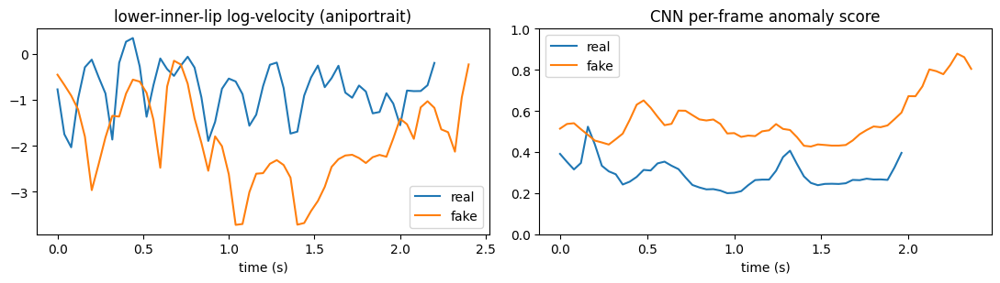

In [15]:
import matplotlib.pyplot as plt
curves = {}                                                # key -> per-frame anomaly score
for k, g in meta.groupby("key"):
    T = len(clip_ch[k]); s, n = np.zeros(T), np.zeros(T)
    for i, st in zip(g.index, g.start): s[st:st + WIN] += sig(frame_logits[i]); n[st:st + WIN] += 1
    curves[k] = np.where(n > 0, s / np.maximum(n, 1), np.nan).astype(np.float32)

te = manifest[manifest.split == "test"]
pair = te.groupby("pair").filter(lambda x: len(x) == 2 and all(k in curves for k in x.key)).pair.iloc[0]
sp, gn, cid = pair.split("/")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for nm in ("real", "fake"):
    k = f"{sp}/{nm}/{gn}/{cid}"; t = np.arange(len(clip_ch[k])) / FPS
    ax[0].plot(t, clip_ch[k][:, CH["lo_inner_vel"]], label=nm); ax[1].plot(t, curves[k], label=nm)
ax[0].set_title("lower-inner-lip log-velocity (" + gn + ")"); ax[1].set_title("CNN per-frame anomaly score"); ax[1].set_ylim(0, 1)
for a in ax: a.set_xlabel("time (s)"); a.legend()
plt.tight_layout(); plt.show()

## 16. Save everything for evaluation / Stage 2

In [16]:
import pickle
(OUT / "models").mkdir(exist_ok=True)
S = C.reset_index()
S[["key", "split", "generator", "label", "clip_id", "z_gbm", "z_cnn", "p_gbm", "p_cnn", "p_ens", "verdict"]].to_csv(OUT / "scores_clip.csv", index=False)
W = meta.copy(); W["z_gbm"] = z_gbm; W["z_cnn"] = z_cnn; W["oof_gbm"] = oof_gbm; W["oof_cnn"] = oof_cnn
W.to_csv(OUT / "scores_window.csv", index=False)
np.savez_compressed(OUT / "frame_curves.npz", **{k.replace("/", "|"): v for k, v in curves.items()})   # per-frame anomaly curves (25 fps)
pd.DataFrame(Fw, columns=W_NAMES).assign(key=meta.key.values, start=meta.start.values).to_csv(OUT / "features_window.csv.gz", index=False)
SIG.to_csv(OUT / "feature_signal_check.csv", index=False); R.to_csv(OUT / "metrics_basic.csv", index=False)
np.save(OUT / "window_channels.npy", Xw); json.dump(CH_NAMES, open(OUT / "channel_names.json", "w"))
pickle.dump(gbm, open(OUT / "models/gbm.pkl", "wb"))
for s, m in zip(CNN_SEEDS, models): torch.save(m.state_dict(), OUT / f"models/cnn_seed{s}.pt")
json.dump(dict(PAIRS=PAIRS, WIN=WIN, STRIDE=STRIDE, GBM_CFG=GBM_CFG, CNN_epochs=fixed_ep, W_CNN=W_CNN, band=[float(LO), float(HI)],
               target_acc=TARGET_ACC, timing_ms_per_clip=TIMING, n_clips=len(C), n_windows=len(meta),
               channel_mean=mu.tolist(), channel_std=sd.tolist(), landmarks=PERIORAL, anchors=ANCHORS),
          open(OUT / "config.json", "w"), indent=1)
print("saved to", OUT, "\n", sorted(p.name for p in OUT.iterdir()))

saved to /content/drive/MyDrive/btp_biolip/outputs 
 ['channel_names.json', 'config.json', 'feature_signal_check.csv', 'features_window.csv.gz', 'frame_curves.npz', 'manifest.csv', 'metrics_basic.csv', 'models', 'scores_clip.csv', 'scores_window.csv', 'window_channels.npy']


## Files for the next person
| file | content |
|---|---|
| `scores_clip.csv` | one row per clip: logits, calibrated probabilities (`p_gbm`, `p_cnn`, `p_ens`), `verdict`. **Train rows are in-sample.** |
| `scores_window.csv` | per 2 s window logits + OOF logits for train windows |
| `frame_curves.npz` | per-frame anomaly curve per clip (key with `/` replaced by `|`), input for Stage 2 |
| `features_window.csv.gz`, `feature_signal_check.csv` | GBM features; per-feature AUC per generator |
| `metrics_basic.csv`, `config.json`, `manifest.csv`, `models/` | basic metrics, settings + band + timing, the clip list (share with the audio team), trained models |

## Notes for the report
- Landmarks are a 64-point perioral subset of MediaPipe's mesh, not BioLip's own scheme. The kinematic features follow BioLip's idea; the classifiers are our own.
- The test generators are unseen, so test results are the real estimate. Validation uses the training generators and is optimistic; calibration and the band come from leave-one-generator-out scores.
- Subset sizes are in `config.json`. Clips with no usable face are dropped (counts in section 7).
- Audio is not used here. The fakes probably keep genuine audio, which is the motivation for Stage 2 cross-alignment.